# Bicep curls: eight-feature orientation-independent model
Train and test a new candidate Isolation Forest using old bicep recordings and new watch recordings. Run All with the project ml/.venv kernel (NumPy, SciPy, scikit-learn, Matplotlib; no pandas needed). Each run saves a separate output folder and never changes the live model.

Seven features use timestamps and raw vector magnitudes. Completion error uses the shortest rotation between the start and end orientations. No pitch/yaw/roll features, per-session amplitude normalization, or existing model/scaler are used.

| Feature | Definition |
|---|---|
| Duration | End minus start timestamp, seconds |
| Completion error | Start-to-end rotation angle, degrees |
| Mean angular speed | Mean gyroscope vector magnitude, degrees/s |
| Peak angular speed | Maximum gyroscope magnitude |
| Angular-speed variability | Standard deviation of gyroscope magnitude |
| Angular path | Integral of gyroscope magnitude, degrees; **not elbow ROM** |
| Acceleration variability | Standard deviation of total acceleration magnitude, g |
| High/low power ratio | Gyroscope magnitude power in 3–8 Hz divided by 0.1–2 Hz |

Magnitudes are invariant to rotation of sensor axes, but sensor placement, bias, noise and movement differences remain. The spectral ratio is exploratory, not a validated tremor measure; short repetitions have coarse frequency resolution. New watch examples are assumed typical, not verified labels. There are no labeled atypical new-watch recordings here.

In [1]:
from pathlib import Path
from datetime import datetime,timezone
import csv,json,re,hashlib,sys,pickle,platform,warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import balanced_accuracy_score,roc_auc_score,confusion_matrix
import sklearn,scipy
REPO=Path('/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo')
WATCH_DIR=Path('/Users/jadechng/Desktop/HomeStretch/recordings/1005')
OUTPUT=Path.cwd()/'bicep_invariant8_runs'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ');OUTPUT.mkdir(parents=True,exist_ok=False)
SEED=42
# First wearing periods only: session ID suffix -> movement window, seconds.
WATCH_WINDOWS={'1d1d07ea':(7,29),'1977cad0':(5,37),'efda0dcf':(5,44),
               '1ce3d7f5':(7,52),'15c80026':(7,37),'53c6c2fd':(6,36)}
# No future samples or full-session amplitude normalization in the 8-feature pipeline.
# Old Apple logger assumptions: user acceleration + gravity in g; gyro in rad/s.
# Negate total acceleration to match the specific-force convention of new/Mbient sensors.
# Verify these conventions and mounting frames before deployment.
REVIEW_STATUS={'watch_labels_confirmed':False,'movement_windows_confirmed':False,
              'sensor_units_and_axes_verified':False,'participant_identity_linkage_verified':False,
              'segmentation_review_passed':False,'live_app_parity_verified':False,
              'deployment_acceptance_criteria_predeclared':False}
print('Outputs:',OUTPUT)

Outputs: /Users/jadechng/Documents/ChatGPT/HomeStretch/bicep_invariant8_runs/20261017T164826403621Z


## 1 Inventory and split before fitting
Use the old **trimmed** files once; exclude repeatedly trimmed variants rather than treating them as independent sessions. Group both arms and both labels by old participant ID. Group new recordings by participant name. Seeded participant splits are created separately within each source: one old participant with atypical examples in validation and a different such participant in test, with remaining old participants in training; 2/1/1 participants for the new watch. Class coverage is selected using labels, never model scores.

These are dataset-local identity groups. If the same person appears under different identifiers across sources, fill in a cross-source identity map before claiming participant independence. The two named Mbient recordings have no verified participant IDs here; they remain an external recording-level check, never training or threshold-selection data. Timestamp-named Mbient files are not added as extra labeled examples.

In [2]:
def readcsv(p):
    with Path(p).open(newline='') as f:return list(csv.DictReader(f))
def digest(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
manifest=[];seen={};duplicates=[]
for label,folder in [(0,'Typical'),(1,'Atypical')]:
    for p in sorted((REPO/'Data/Trimmed'/folder).glob('*.csv')):
        if p.name.startswith('Trimmed_Trimmed_'):duplicates.append({'file':str(p),'reason':'repeatedly trimmed variant excluded'});continue
        match=re.search(r'(\d{3})_BicepCurl_([LR])_',p.name,re.I)
        if not match:continue
        h=digest(p)
        if h in seen:duplicates.append({'file':str(p),'reason':'exact duplicate','duplicate_of':seen[h]});continue
        seen[h]=str(p)
        manifest.append(dict(source='old',file=str(p),gyro_file=None,label=label,label_status='folder label',participant='old:'+match[1],side=match[2],sha256=h,window=None))
for p in sorted(WATCH_DIR.glob('*.csv')):
    m=json.loads(p.with_suffix('.json').read_text());h=m.get('homestretch',{})
    if h.get('exercise_id')!='bicep_curl':continue
    key=p.stem.rsplit('_',1)[-1]
    manifest.append(dict(source='watch',file=str(p),gyro_file=None,label=0,label_status='ASSUMED typical; unreviewed',participant='watch:'+h.get('patient_id','unknown').strip().lower(),side=h.get('side'),sha256=digest(p),window=WATCH_WINDOWS.get(key)))
for prefix,label in [('Typical',0),('left_atypical',1)]:
    a=REPO/'mbientcode/mbientdata'/f'{prefix}_Accelerometer.csv';g=a.with_name(f'{prefix}_Gyroscope.csv')
    if a.exists() and g.exists():manifest.append(dict(source='mbient',file=str(a),gyro_file=str(g),label=label,label_status='filename label; execution details unverified',participant='mbient:unknown',side='unknown',sha256=digest(a),gyro_sha256=digest(g),window=None))
rng=np.random.default_rng(SEED);split_map={}
for source in ['old','watch']:
    ids=sorted({r['participant'] for r in manifest if r['source']==source});ids=list(rng.permutation(ids))
    assert len(ids)>=4, f'Need at least four {source} participant groups.'
    ntest=max(1,len(ids)//5);nval=max(1,len(ids)//5)
    if source=='old':
        # Class-coverage constraint uses labels only, never features/scores.
        atypical_ids=[pid for pid in ids if any(r['participant']==pid and r['label']==1 for r in manifest)]
        assert len(atypical_ids)>=2,'Need distinct atypical participant groups for validation and test.'
        test_ids={atypical_ids[0]};val_ids={atypical_ids[1]}
        for pid in ids:split_map[pid]='test' if pid in test_ids else 'validation' if pid in val_ids else 'train'
    else:
        for i,pid in enumerate(ids):split_map[pid]='test' if i<ntest else 'validation' if i<ntest+nval else 'train'
for i,r in enumerate(manifest):r['session_id']=f'session_{i:03d}';r['split']='external' if r['source']=='mbient' else split_map[r['participant']]
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,indent=2));(OUTPUT/'excluded_files.json').write_text(json.dumps(duplicates,indent=2))
print(json.dumps(split_map,indent=2))
for source in ['old','watch','mbient']:print(source,sum(r['source']==source for r in manifest),'files')

{
  "old:004": "train",
  "old:001": "train",
  "old:009": "train",
  "old:003": "test",
  "old:005": "train",
  "old:007": "validation",
  "old:002": "train",
  "old:006": "train",
  "old:011": "train",
  "watch:arshaan": "test",
  "watch:angel": "validation",
  "watch:anisha": "train",
  "watch:ashritha": "train"
}
old 20 files
watch 6 files
mbient 2 files


## 2 Shared preprocessing and complete repetitions
Convert all sources to acceleration including gravity in g and gyroscope in degrees/s. Align to a 50 Hz grid using previous samples only; exclude stale data and reset on gaps longer than 60 ms. Estimate gyro bias only when at least one second of the existing initial lead-in meets the stationary check. This initialization must finish before live rep feedback starts. No additional recording is required.

A gyro/gravity quaternion estimator supplies start-to-end completion error and rotation excursion for segmentation. It never converts to Euler angles. Gravity feedback is gated by acceleration magnitude. A trailing five-sample mean smooths the **segmentation excursion only**; feature magnitudes retain the frequency band used for the spectral ratio.

A full excursion rise and return defines a candidate curl. The next rise confirms its end, causing a recorded delay and potentially leaving the final rep unconfirmed. We do not segment on gyroscope magnitude peaks, which can occur twice per curl. Boundaries remain experimental and must be checked in the review plot. Completion error is not used to exclude abnormal repetitions.

No zero-centering or amplitude normalization of the magnitude signals: these would change their physical meaning. Only the spectral calculation removes its mean. The model scaler is fitted later, on training features only.

In [3]:
"""Experimental eight-feature pipeline. Fixed sensor rotations preserve magnitudes; placement and sensor errors still matter."""
import numpy as np
from scipy.spatial.transform import Rotation
from collections import deque
from itertools import combinations
FS=50.0
FEATURES=['duration_seconds','completion_error_deg','gyro_mean_deg_s','gyro_peak_deg_s','gyro_std_deg_s','angular_path_deg','accel_magnitude_std_g','gyro_high_low_power_ratio']

class OrientationStream:
    def __init__(self):
        self.r=None; self.r0=None; self.last=None; self.prev=None; self.unwrapped=None;self.history=deque(maxlen=5)
    def update(self,t,accel,gyro):
        if self.last is not None and t-self.last>.060001:self.__init__()
        if self.r is None:
            if not .5<np.linalg.norm(accel)<1.5:return None
            x,y,z=accel; self.r=Rotation.from_euler('xyz',[np.arctan2(y,z),np.arctan2(-x,np.hypot(y,z)),0]);self.r0=self.r
        else:
            dt=t-self.last; omega=np.deg2rad(gyro)
            norm=np.linalg.norm(accel)
            if .85<=norm<=1.15:omega+=.5*np.cross(accel/norm,self.r.inv().apply([0,0,1]))
            self.r=self.r*Rotation.from_rotvec(omega*dt)
        self.last=t
        relative=self.r0.inv()*self.r
        excursion=np.rad2deg(relative.magnitude())
        return self.r.as_quat(),excursion

class RepStream:
    """Confirm each trough after a fixed 8-degree rise. Feedback occurs at emitted_at."""
    def __init__(self):self.mode='seek';self.low=None;self.high=None;self.start=None
    def update(self,i,value):
        if self.low is None:self.low=(i,value);return None
        if self.mode in ['seek','rise']:
            if value<self.low[1]:self.low=(i,value)
            if self.mode=='seek' and value-self.low[1]>=15:
                self.start=self.low[0];self.high=(i,value);self.mode='rise'
            elif self.mode=='rise':
                if self.high is None or value>self.high[1]:self.high=(i,value)
                if self.high[1]-value>=8:self.low=(i,value);self.mode='fall'
        else:
            if value<self.low[1]:self.low=(i,value)
            if value-self.low[1]>=8:
                result=(self.start,self.low[0],i)
                self.start=self.low[0];self.high=(i,value);self.mode='rise'
                return result
        return None

def features(t,q,accel,gyro):
    speed=np.linalg.norm(gyro,axis=1)
    # Endpoint orientation distance, not Euler-angle summation.
    error=np.rad2deg((Rotation.from_quat(q[0]).inv()*Rotation.from_quat(q[-1])).magnitude())
    from scipy.signal import periodogram
    freq,power=periodogram(speed,fs=FS,window='hann',detrend='constant',scaling='spectrum')
    low=float(power[(freq>=.1)&(freq<=2)].sum())
    high=float(power[(freq>=3)&(freq<=8)].sum())
    values=[t[-1]-t[0],error,speed.mean(),speed.max(),speed.std(),np.trapezoid(speed,t),np.linalg.norm(accel,axis=1).std(),high/max(low,1e-8)]
    return dict(zip(FEATURES,map(float,values)))

def align_streams(accel,gyro):
    # Inputs N x 4: seconds,x,y,z. Previous-observation hold never reads a future sample.
    a=accel[np.isfinite(accel).all(axis=1)];g=gyro[np.isfinite(gyro).all(axis=1)]
    if min(len(a),len(g))<5:return np.empty((0,8))
    if not (np.all(np.diff(a[:,0])>0) and np.all(np.diff(g[:,0])>0)):raise ValueError('Nonmonotonic timestamps')
    t=np.arange(max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0])+1e-8,1/FS)
    ai=np.searchsorted(a[:,0],t,side='right')-1;gi=np.searchsorted(g[:,0],t,side='right')-1
    age=np.maximum(t-a[ai,0],t-g[gi,0]);good=age<=.060001
    return np.column_stack([t[good],a[ai[good],1:],g[gi[good],1:],age[good]])

def process(accel,gyro,window):
    joined=align_streams(accel,gyro)
    # Existing stationary lead-in only. Never estimate bias from moving repetitions.
    lead=joined[(joined[:,0]<min(window[0],2))] if len(joined) else joined
    bias=np.zeros(3)
    if len(lead)>=50 and np.std(np.linalg.norm(lead[:,1:4],axis=1))<.03 and np.max(np.linalg.norm(lead[:,4:7],axis=1))<5:
        bias=np.mean(lead[:,4:7],axis=0)
    state=OrientationStream();detector=RepStream();trace=[];raw=[];accepted=[];rejected=[];block=0;last=None;history=deque(maxlen=5)
    for row in joined:
        t=row[0];gyro=row[4:7]-bias
        if last is not None and t-last>.060001:detector=RepStream();history.clear();block+=1
        last=t
        value=state.update(t,row[1:4],gyro)
        if value is None:continue
        quat,excursion=value;history.append(excursion);excursion=float(np.mean(history))
        index=len(trace)
        trace.append([t,0,0,0,excursion,row[7],0,block])
        raw.append([t,*quat,*row[1:4],*gyro])
        if t<window[0] or t>window[1]:detector=RepStream();continue
        result=detector.update(index,excursion)
        if result is None:continue
        start,end,emit=result;rep=np.array(trace[start:end+1]);data=np.array(raw[start:end+1]);duration=rep[-1,0]-rep[0,0]
        reasons=[]
        if not .6<=duration<=8:reasons.append('duration outside engineering bounds')
        if np.ptp(rep[:,4])<15:reasons.append('excursion below 15 degrees')
        if np.mean(rep[:,5]>.04)>.1:reasons.append('excess stale sensor samples')
        record={'start_sec':float(rep[0,0]),'end_sec':float(rep[-1,0]),'emitted_at_sec':float(t),'feedback_delay_sec':float(t-rep[-1,0]),'block':block,'held_sample_fraction':float(np.mean(rep[:,5]>.002))}
        if reasons:rejected.append(dict(record,reason='; '.join(reasons)))
        else:accepted.append(dict(record,**features(data[:,0],data[:,1:5],data[:,5:8],data[:,8:11])))
    return accepted,rejected,np.asarray(trace)

In [4]:
def load_streams(r):
    data=readcsv(r['file']);source=r['source']
    if source=='old':
        t=np.array([float(x['seconds_elapsed']) for x in data]);t-=t[0]
        gravity=np.array([[float(x['gravity'+c]) for c in 'XYZ'] for x in data])
        user=np.array([[float(x['acceleration'+c]) for c in 'XYZ'] for x in data])
        gyro=np.rad2deg([[float(x['rotationRate'+c]) for c in 'XYZ'] for x in data])
        return np.column_stack([t,-(gravity+user)]),np.column_stack([t,gyro])
    if source=='watch':
        # Use the project's protocol reader to validate IDs, timestamps, sequence and validity.
        sys.path.insert(0,str(REPO/'signal-processing'))
        from session_pipeline.reader import load_recording
        rec=load_recording(r['file']);streams=rec['streams']
        return tuple(streams[k][streams[k][:,4]>0,:4] for k in ['acceleration','gyroscope'])
    def mb(p):
        rows=readcsv(p);keys=list(rows[0])
        return np.array([[float(x[keys[0]])/1000,*[float(x[k]) for k in keys[3:6]]] for x in rows])
    a,g=mb(r['file']),mb(r['gyro_file']);origin=min(a[0,0],g[0,0]);a[:,0]-=origin;g[:,0]-=origin
    return a,g # actual epoch timestamps, not separately zeroed elapsed columns

# Prefix invariance: appended samples must not alter already-emitted angles or reps.
t=np.arange(0,10,1/FS);theta=.7*(1-np.cos(2*np.pi*t/2))
a=np.column_stack([t,np.zeros(len(t)),np.sin(theta),np.cos(theta)])
g=np.column_stack([t,np.rad2deg(.7*np.pi*np.sin(np.pi*t)),np.zeros((len(t),2))])
full=process(a,g,(0,10));prefix=process(a[:300],g[:300],(0,10))
assert np.allclose(full[2][:len(prefix[2])],prefix[2])
assert [r for r in full[0] if r['emitted_at_sec']<=t[299]]==prefix[0]
assert len(FEATURES)==8
# Fixed sensor-axis rotation must preserve all eight feature definitions.
rot=Rotation.from_euler('xyz',[37,-24,63],degrees=True)
q=Rotation.from_rotvec(np.column_stack([theta,np.zeros((len(t),2))]))
f1=features(t,q.as_quat(),a[:,1:],g[:,1:])
f2=features(t,(q*rot.inv()).as_quat(),rot.apply(a[:,1:]),rot.apply(g[:,1:]))
assert np.allclose(list(f1.values()),list(f2.values()),rtol=1e-9,atol=1e-9)
print('Passed eight-feature fixed-axis-rotation invariance check.')
print('Passed prefix invariance check for orientation, smoothing and emitted repetitions.')

Passed eight-feature fixed-axis-rotation invariance check.
Passed prefix invariance check for orientation, smoothing and emitted repetitions.


## 3 Extract and review repetitions
Plots shade accepted candidate intervals. Check for missed reps, merged reps, rest and handling before changing review flags. All new first wearing periods are plotted; no second wearing period is silently included. Exported exclusions and counts expose data-quality failures instead of labeling them atypical.

old train typical 174 atypical 23
old validation typical 28 atypical 15
old test typical 28 atypical 27
watch train typical 27 atypical 0
watch validation typical 19 atypical 0
watch test typical 9 atypical 0
mbient external typical 14 atypical 16
Errors: []


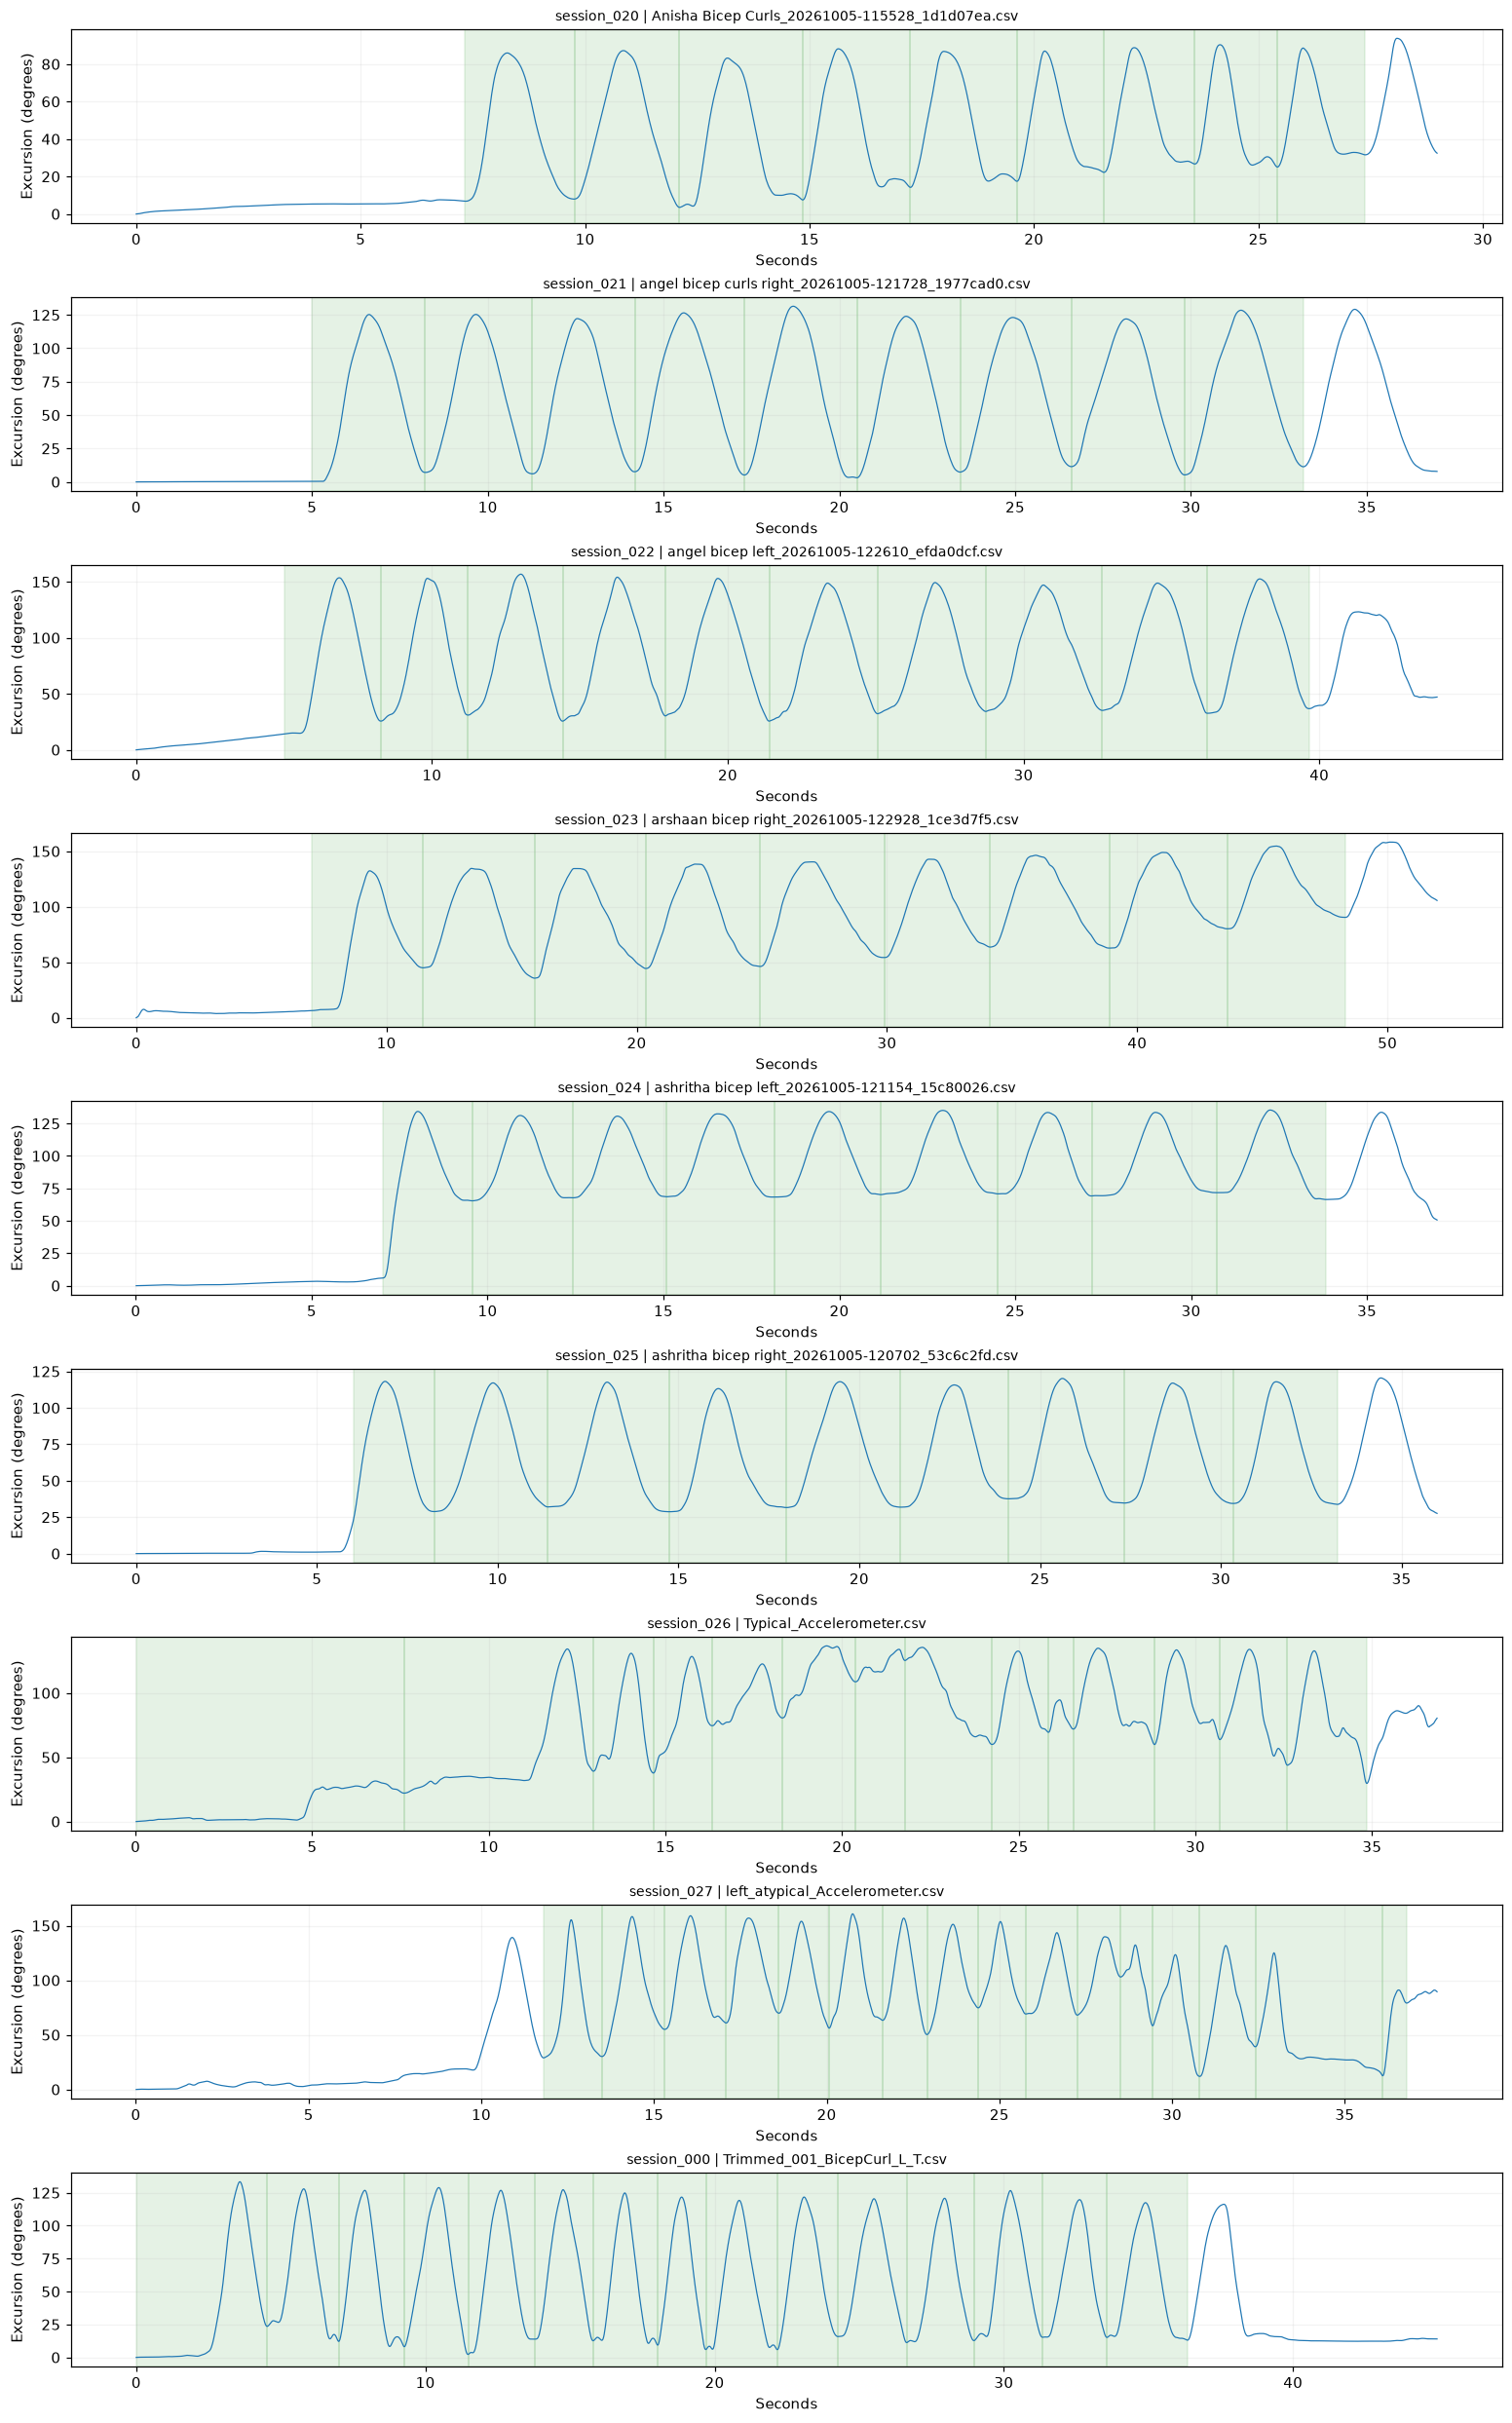

In [5]:
features_rows=[];rejections=[];session_audit=[];traces={}
for r in manifest:
    try:
        if r['source']=='watch' and r['window'] is None:raise ValueError('Missing movement window')
        a,g=load_streams(r)
        window=r['window'] or (max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0]))
        # Exclude later handling from watch reconstruction; retain its initial pose.
        a=a[a[:,0]<=window[1]];g=g[g[:,0]<=window[1]]
        accepted,rejected,trace=process(a,g,window);traces[r['session_id']]=trace
        tags={k:r[k] for k in ['session_id','source','participant','side','label','label_status','split']}
        features_rows.extend(dict(tags,**x) for x in accepted)
        rejections.extend(dict(tags,**x) for x in rejected)
        session_audit.append(dict(tags,accepted=len(accepted),rejected=len(rejected),error=''))
    except (ValueError,KeyError,IndexError) as e:session_audit.append(dict(session_id=r['session_id'],source=r['source'],accepted=0,rejected=0,error=str(e)))
def save_table(name,rows):
    if not rows:return
    fields=list(dict.fromkeys(k for r in rows for k in r))
    with (OUTPUT/name).open('w',newline='') as f:w=csv.DictWriter(f,fieldnames=fields);w.writeheader();w.writerows(rows)
save_table('features.csv',features_rows);save_table('rejected_candidates.csv',rejections);save_table('session_audit.csv',session_audit)
for source in ['old','watch','mbient']:
    for split in ['train','validation','test','external']:
        group=[r for r in features_rows if r['source']==source and r['split']==split]
        if group:print(source,split,'typical',sum(r['label']==0 for r in group),'atypical',sum(r['label']==1 for r in group))
print('Errors:',[r for r in session_audit if r['error']])
selected=[r for r in manifest if r['source'] in ['watch','mbient']]+[next(r for r in manifest if r['source']=='old')]
fig,axes=plt.subplots(len(selected),1,figsize=(14,2.5*len(selected)),constrained_layout=True)
for ax,r in zip(axes,selected):
    trace=traces.get(r['session_id'],np.empty((0,8)))
    if len(trace):
        for b in np.unique(trace[:,-1]):
            z=trace[trace[:,-1]==b];ax.plot(z[:,0],z[:,4],lw=.8)
    for f in features_rows:
        if f['session_id']==r['session_id']:ax.axvspan(f['start_sec'],f['end_sec'],color='green',alpha=.1)
    ax.set_title(r['session_id']+' | '+Path(r['file']).name,fontsize=9);ax.set_ylabel('Excursion (degrees)');ax.set_xlabel('Seconds');ax.grid(alpha=.15)
fig.savefig(OUTPUT/'segmentation_review.png',dpi=110);plt.show()

## 4 Fit scalers and forests on typical training repetitions
Fit two fresh eight-feature models: old-only and pooled old plus new watch. Cap each training participant at 20 repetitions without replacement, retaining all available repetitions for smaller groups. Report training sample counts; this limits but does not eliminate source imbalance. Forest hyperparameters are fixed in advance.

Select each threshold using participant-weighted balanced accuracy on its validation participants. A typical-only validation fallback uses the 95th percentile and cannot calibrate sensitivity. No test or external Mbient scores select thresholds. Label assumptions and small participant counts limit the conclusions.

In [6]:
X=np.array([[r[k] for k in FEATURES] for r in features_rows]);assert np.isfinite(X).all()
y=np.array([r['label'] for r in features_rows]);parts=np.array([r['split'] for r in features_rows]);sources=np.array([r['source'] for r in features_rows]);people=np.array([r['participant'] for r in features_rows])
assert all(not(set(people[parts==a])&set(people[parts==b])) for a,b in [('train','validation'),('train','test'),('validation','test')])
models={}
for name,allowed in [('old_only',['old']),('pooled',['old','watch'])]:
    train=np.flatnonzero((parts=='train')&(y==0)&np.isin(sources,allowed));ids=np.unique(people[train])
    assert len(ids)>=2,'Too few usable training participants.'
    count=20;rng=np.random.default_rng(SEED)
    train=np.concatenate([rng.choice(train[people[train]==p],min(count,sum(people[train]==p)),replace=False) for p in ids])
    scaler=StandardScaler().fit(X[train]);forest=IsolationForest(n_estimators=300,contamination='auto',random_state=SEED,n_jobs=-1).fit(scaler.transform(X[train]))
    scores=-forest.decision_function(scaler.transform(X))
    val=np.flatnonzero((parts=='validation')&np.isin(sources,allowed))
    assert len(val)>0 and np.any(y[val]==0),'Need typical validation repetitions.'
    if len(np.unique(y[val]))==2:
        weights=np.array([1/sum(people[val]==p) for p in people[val]])
        thresholds=np.r_[scores[val].min()-1e-8,np.unique(scores[val]),scores[val].max()+1e-8]
        quality=[balanced_accuracy_score(y[val],scores[val]>th,sample_weight=weights) for th in thresholds]
        threshold=float(thresholds[int(np.argmax(quality))]);method='participant-weighted validation balanced accuracy'
    else:threshold=float(np.quantile(scores[val][y[val]==0],.95));method='typical validation 95th percentile; no sensitivity calibration'
    models[name]=dict(scaler=scaler,forest=forest,threshold=threshold,scores=scores,threshold_method=method,training_indices=train.tolist())
    print(name,'training reps:',len(train),'participants:',len(ids),'threshold:',threshold,'method:',method)

old_only training reps: 135 participants: 7 threshold: 0.12465752284803167 method: participant-weighted validation balanced accuracy
pooled training reps: 162 participants: 9 threshold: 0.14598264652639736 method: participant-weighted validation balanced accuracy


## 5 Held-out evaluation and external Mbient check
Compare old-only and pooled models on the same held-out rows. Report false-positive rate on typical recordings, sensitivity on atypical recordings when available, and each participant separately. Missing classes produce missing metrics, not an invented accuracy score.

The small test sets and unreviewed new-watch labels make this a pilot. Mbient results are recording-level results with unknown participant linkage. If test results are used to revise the pipeline, this split is no longer a final untouched test.

[
  {
    "model": "old_only",
    "group": "old",
    "repetitions": 55,
    "participants": 1,
    "tn": 28,
    "fp": 0,
    "fn": 7,
    "tp": 20,
    "false_positive_rate": 0.0,
    "sensitivity": 0.7407407407407407,
    "auroc": 0.9986772486772487
  },
  {
    "model": "old_only",
    "group": "old/old:003",
    "repetitions": 55,
    "participants": 1,
    "tn": 28,
    "fp": 0,
    "fn": 7,
    "tp": 20,
    "false_positive_rate": 0.0,
    "sensitivity": 0.7407407407407407,
    "auroc": 0.9986772486772487
  },
  {
    "model": "old_only",
    "group": "watch",
    "repetitions": 9,
    "participants": 1,
    "tn": 9,
    "fp": 0,
    "fn": 0,
    "tp": 0,
    "false_positive_rate": 0.0,
    "sensitivity": null,
    "auroc": null
  },
  {
    "model": "old_only",
    "group": "watch/watch:arshaan",
    "repetitions": 9,
    "participants": 1,
    "tn": 9,
    "fp": 0,
    "fn": 0,
    "tp": 0,
    "false_positive_rate": 0.0,
    "sensitivity": null,
    "auroc": null
  },
  {
  

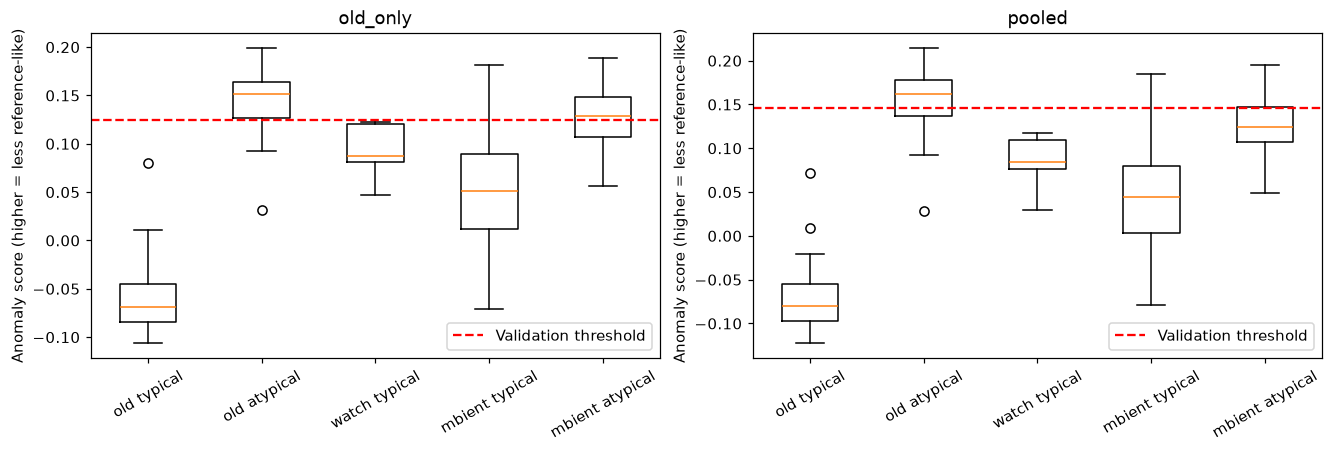

In [7]:
metrics=[]
def evaluate(name,mask,group):
    idx=np.flatnonzero(mask)
    if not len(idx):return
    m=models[name];truth=y[idx];pred=m['scores'][idx]>m['threshold'];tn,fp,fn,tp=confusion_matrix(truth,pred,labels=[0,1]).ravel()
    metrics.append(dict(model=name,group=group,repetitions=len(idx),participants=None if np.any(sources[idx]=='mbient') else len(set(people[idx])),tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),false_positive_rate=float(fp/(tn+fp)) if tn+fp else None,sensitivity=float(tp/(tp+fn)) if tp+fn else None,auroc=float(roc_auc_score(truth,m['scores'][idx])) if len(set(truth))==2 else None))
for name in models:
    for source in ['old','watch','mbient']:
        mask=(sources==source)&np.isin(parts,['test','external']);evaluate(name,mask,source)
        for person in sorted(set(people[mask])):evaluate(name,mask&(people==person),source+'/'+person)
print(json.dumps(metrics,indent=2));save_table('evaluation.csv',metrics)
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for ax,name in zip(axes,models):
    groups=[];labels=[]
    for source in ['old','watch','mbient']:
        for label in [0,1]:
            values=models[name]['scores'][(sources==source)&(y==label)&np.isin(parts,['test','external'])]
            if len(values):groups.append(values);labels.append(source+' '+('typical' if label==0 else 'atypical'))
    ax.boxplot(groups,tick_labels=labels);ax.axhline(models[name]['threshold'],color='red',ls='--',label='Validation threshold');ax.tick_params(axis='x',labelrotation=30);ax.set_title(name);ax.set_ylabel('Anomaly score (higher = less reference-like)');ax.legend()
plt.show()

## 6 Export candidate models
Save both fitted forests and scalers, feature order, threshold, preprocessing source and audit results. The pooled model is the candidate, not an automatic replacement. It expects eight features, whereas the existing app model expects four.

Before replacement, review segmentation, verify source units and labels, and replay these same recordings through the live integration to establish parity. There is no labeled atypical watch test here, so watch sensitivity remains unknown. Do not deploy based solely on this notebook's results.

In [8]:
metadata={'schema_version':'bicep-causal8-pilot-v1','feature_order':FEATURES,'sampling_rate_hz':FS,
          'score_convention':'negative decision_function; atypical when score > threshold',
          'threshold':models['pooled']['threshold'],'threshold_method':models['pooled']['threshold_method'],
          'seed':SEED,'versions':{'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'sklearn':sklearn.__version__},
          'input_contract':{'accelerometer':'timestamp seconds plus XYZ in g, sensor specific force','gyroscope':'same-clock timestamp seconds plus XYZ degrees/s','invalid_samples':'discard before resampling; gaps trigger resets','state':'preserve orientation, smoother and segmenter state across live callbacks','output':'8 ordered features only after a confirmed complete candidate'},'review_status':REVIEW_STATUS,'limitations':['Magnitude invariance does not remove placement, bias or device differences','New labels assumed typical','Old acceleration sign and gyro-unit assumptions unverified','Second watch placements excluded','Mbient participant identities unknown','No clinical accuracy claim'],
          'segmentation':{'excursion_trigger_deg':15,'reversal_deg':8,'minimum_duration_sec':.6,'maximum_duration_sec':8,'last_rep_may_be_unconfirmed':True},
          'fusion':{'gravity_gain_per_sec':.5,'gravity_gate_g':[.85,1.15],'gyro_bias_correction':'stationary initial lead-in when available','max_sample_age_sec':.06,'smoothing':'trailing mean 5 samples on segmentation excursion only'},
          'replaces':'mbientcode/isolation_forest.pkl only after a separate tested app integration'}
for name,m in models.items():
    bundle=OUTPUT/name;bundle.mkdir()
    for key in ['scaler','forest']:
        with (bundle/(key+'.pkl')).open('wb') as f:pickle.dump(m[key],f)
    (bundle/'metadata.json').write_text(json.dumps(dict(metadata,threshold=m['threshold'],threshold_method=m['threshold_method']),indent=2))
# Verify saved pooled artifacts reproduce the scores on the same runtime.
with (OUTPUT/'pooled/forest.pkl').open('rb') as f:restored=pickle.load(f)
with (OUTPUT/'pooled/scaler.pkl').open('rb') as f:restored_scaler=pickle.load(f)
assert np.allclose(-restored.decision_function(restored_scaler.transform(X)),models['pooled']['scores'])
blockers=[k for k,v in REVIEW_STATUS.items() if not v]
status={'ready_to_replace':False,'status':'experimental candidate only','blockers':blockers,'active_model_changed':False}
(OUTPUT/'promotion_status.json').write_text(json.dumps(status,indent=2))
print('Exported:',OUTPUT/'pooled');print(json.dumps(status,indent=2))

Exported: /Users/jadechng/Documents/ChatGPT/HomeStretch/bicep_invariant8_runs/20261017T164826403621Z/pooled
{
  "ready_to_replace": false,
  "status": "experimental candidate only",
  "blockers": [
    "watch_labels_confirmed",
    "movement_windows_confirmed",
    "sensor_units_and_axes_verified",
    "participant_identity_linkage_verified",
    "segmentation_review_passed",
    "live_app_parity_verified",
    "deployment_acceptance_criteria_predeclared"
  ],
  "active_model_changed": false
}


In [9]:
(OUTPUT/'pooled'/'preprocessing.py').write_text('"""Experimental eight-feature pipeline. Fixed sensor rotations preserve magnitudes; placement and sensor errors still matter."""\nimport numpy as np\nfrom scipy.spatial.transform import Rotation\nfrom collections import deque\nfrom itertools import combinations\nFS=50.0\nFEATURES=[\'duration_seconds\',\'completion_error_deg\',\'gyro_mean_deg_s\',\'gyro_peak_deg_s\',\'gyro_std_deg_s\',\'angular_path_deg\',\'accel_magnitude_std_g\',\'gyro_high_low_power_ratio\']\n\nclass OrientationStream:\n    def __init__(self):\n        self.r=None; self.r0=None; self.last=None; self.prev=None; self.unwrapped=None;self.history=deque(maxlen=5)\n    def update(self,t,accel,gyro):\n        if self.last is not None and t-self.last>.060001:self.__init__()\n        if self.r is None:\n            if not .5<np.linalg.norm(accel)<1.5:return None\n            x,y,z=accel; self.r=Rotation.from_euler(\'xyz\',[np.arctan2(y,z),np.arctan2(-x,np.hypot(y,z)),0]);self.r0=self.r\n        else:\n            dt=t-self.last; omega=np.deg2rad(gyro)\n            norm=np.linalg.norm(accel)\n            if .85<=norm<=1.15:omega+=.5*np.cross(accel/norm,self.r.inv().apply([0,0,1]))\n            self.r=self.r*Rotation.from_rotvec(omega*dt)\n        self.last=t\n        relative=self.r0.inv()*self.r\n        excursion=np.rad2deg(relative.magnitude())\n        return self.r.as_quat(),excursion\n\nclass RepStream:\n    """Confirm each trough after a fixed 8-degree rise. Feedback occurs at emitted_at."""\n    def __init__(self):self.mode=\'seek\';self.low=None;self.high=None;self.start=None\n    def update(self,i,value):\n        if self.low is None:self.low=(i,value);return None\n        if self.mode in [\'seek\',\'rise\']:\n            if value<self.low[1]:self.low=(i,value)\n            if self.mode==\'seek\' and value-self.low[1]>=15:\n                self.start=self.low[0];self.high=(i,value);self.mode=\'rise\'\n            elif self.mode==\'rise\':\n                if self.high is None or value>self.high[1]:self.high=(i,value)\n                if self.high[1]-value>=8:self.low=(i,value);self.mode=\'fall\'\n        else:\n            if value<self.low[1]:self.low=(i,value)\n            if value-self.low[1]>=8:\n                result=(self.start,self.low[0],i)\n                self.start=self.low[0];self.high=(i,value);self.mode=\'rise\'\n                return result\n        return None\n\ndef features(t,q,accel,gyro):\n    speed=np.linalg.norm(gyro,axis=1)\n    # Endpoint orientation distance, not Euler-angle summation.\n    error=np.rad2deg((Rotation.from_quat(q[0]).inv()*Rotation.from_quat(q[-1])).magnitude())\n    from scipy.signal import periodogram\n    freq,power=periodogram(speed,fs=FS,window=\'hann\',detrend=\'constant\',scaling=\'spectrum\')\n    low=float(power[(freq>=.1)&(freq<=2)].sum())\n    high=float(power[(freq>=3)&(freq<=8)].sum())\n    values=[t[-1]-t[0],error,speed.mean(),speed.max(),speed.std(),np.trapezoid(speed,t),np.linalg.norm(accel,axis=1).std(),high/max(low,1e-8)]\n    return dict(zip(FEATURES,map(float,values)))\n\ndef align_streams(accel,gyro):\n    # Inputs N x 4: seconds,x,y,z. Previous-observation hold never reads a future sample.\n    a=accel[np.isfinite(accel).all(axis=1)];g=gyro[np.isfinite(gyro).all(axis=1)]\n    if min(len(a),len(g))<5:return np.empty((0,8))\n    if not (np.all(np.diff(a[:,0])>0) and np.all(np.diff(g[:,0])>0)):raise ValueError(\'Nonmonotonic timestamps\')\n    t=np.arange(max(a[0,0],g[0,0]),min(a[-1,0],g[-1,0])+1e-8,1/FS)\n    ai=np.searchsorted(a[:,0],t,side=\'right\')-1;gi=np.searchsorted(g[:,0],t,side=\'right\')-1\n    age=np.maximum(t-a[ai,0],t-g[gi,0]);good=age<=.060001\n    return np.column_stack([t[good],a[ai[good],1:],g[gi[good],1:],age[good]])\n\ndef process(accel,gyro,window):\n    joined=align_streams(accel,gyro)\n    # Existing stationary lead-in only. Never estimate bias from moving repetitions.\n    lead=joined[(joined[:,0]<min(window[0],2))] if len(joined) else joined\n    bias=np.zeros(3)\n    if len(lead)>=50 and np.std(np.linalg.norm(lead[:,1:4],axis=1))<.03 and np.max(np.linalg.norm(lead[:,4:7],axis=1))<5:\n        bias=np.mean(lead[:,4:7],axis=0)\n    state=OrientationStream();detector=RepStream();trace=[];raw=[];accepted=[];rejected=[];block=0;last=None;history=deque(maxlen=5)\n    for row in joined:\n        t=row[0];gyro=row[4:7]-bias\n        if last is not None and t-last>.060001:detector=RepStream();history.clear();block+=1\n        last=t\n        value=state.update(t,row[1:4],gyro)\n        if value is None:continue\n        quat,excursion=value;history.append(excursion);excursion=float(np.mean(history))\n        index=len(trace)\n        trace.append([t,0,0,0,excursion,row[7],0,block])\n        raw.append([t,*quat,*row[1:4],*gyro])\n        if t<window[0] or t>window[1]:detector=RepStream();continue\n        result=detector.update(index,excursion)\n        if result is None:continue\n        start,end,emit=result;rep=np.array(trace[start:end+1]);data=np.array(raw[start:end+1]);duration=rep[-1,0]-rep[0,0]\n        reasons=[]\n        if not .6<=duration<=8:reasons.append(\'duration outside engineering bounds\')\n        if np.ptp(rep[:,4])<15:reasons.append(\'excursion below 15 degrees\')\n        if np.mean(rep[:,5]>.04)>.1:reasons.append(\'excess stale sensor samples\')\n        record={\'start_sec\':float(rep[0,0]),\'end_sec\':float(rep[-1,0]),\'emitted_at_sec\':float(t),\'feedback_delay_sec\':float(t-rep[-1,0]),\'block\':block,\'held_sample_fraction\':float(np.mean(rep[:,5]>.002))}\n        if reasons:rejected.append(dict(record,reason=\'; \'.join(reasons)))\n        else:accepted.append(dict(record,**features(data[:,0],data[:,1:5],data[:,5:8],data[:,8:11])))\n    return accepted,rejected,np.asarray(trace)\n')
print('Saved exact replay preprocessing source with the candidate bundle.')

Saved exact replay preprocessing source with the candidate bundle.


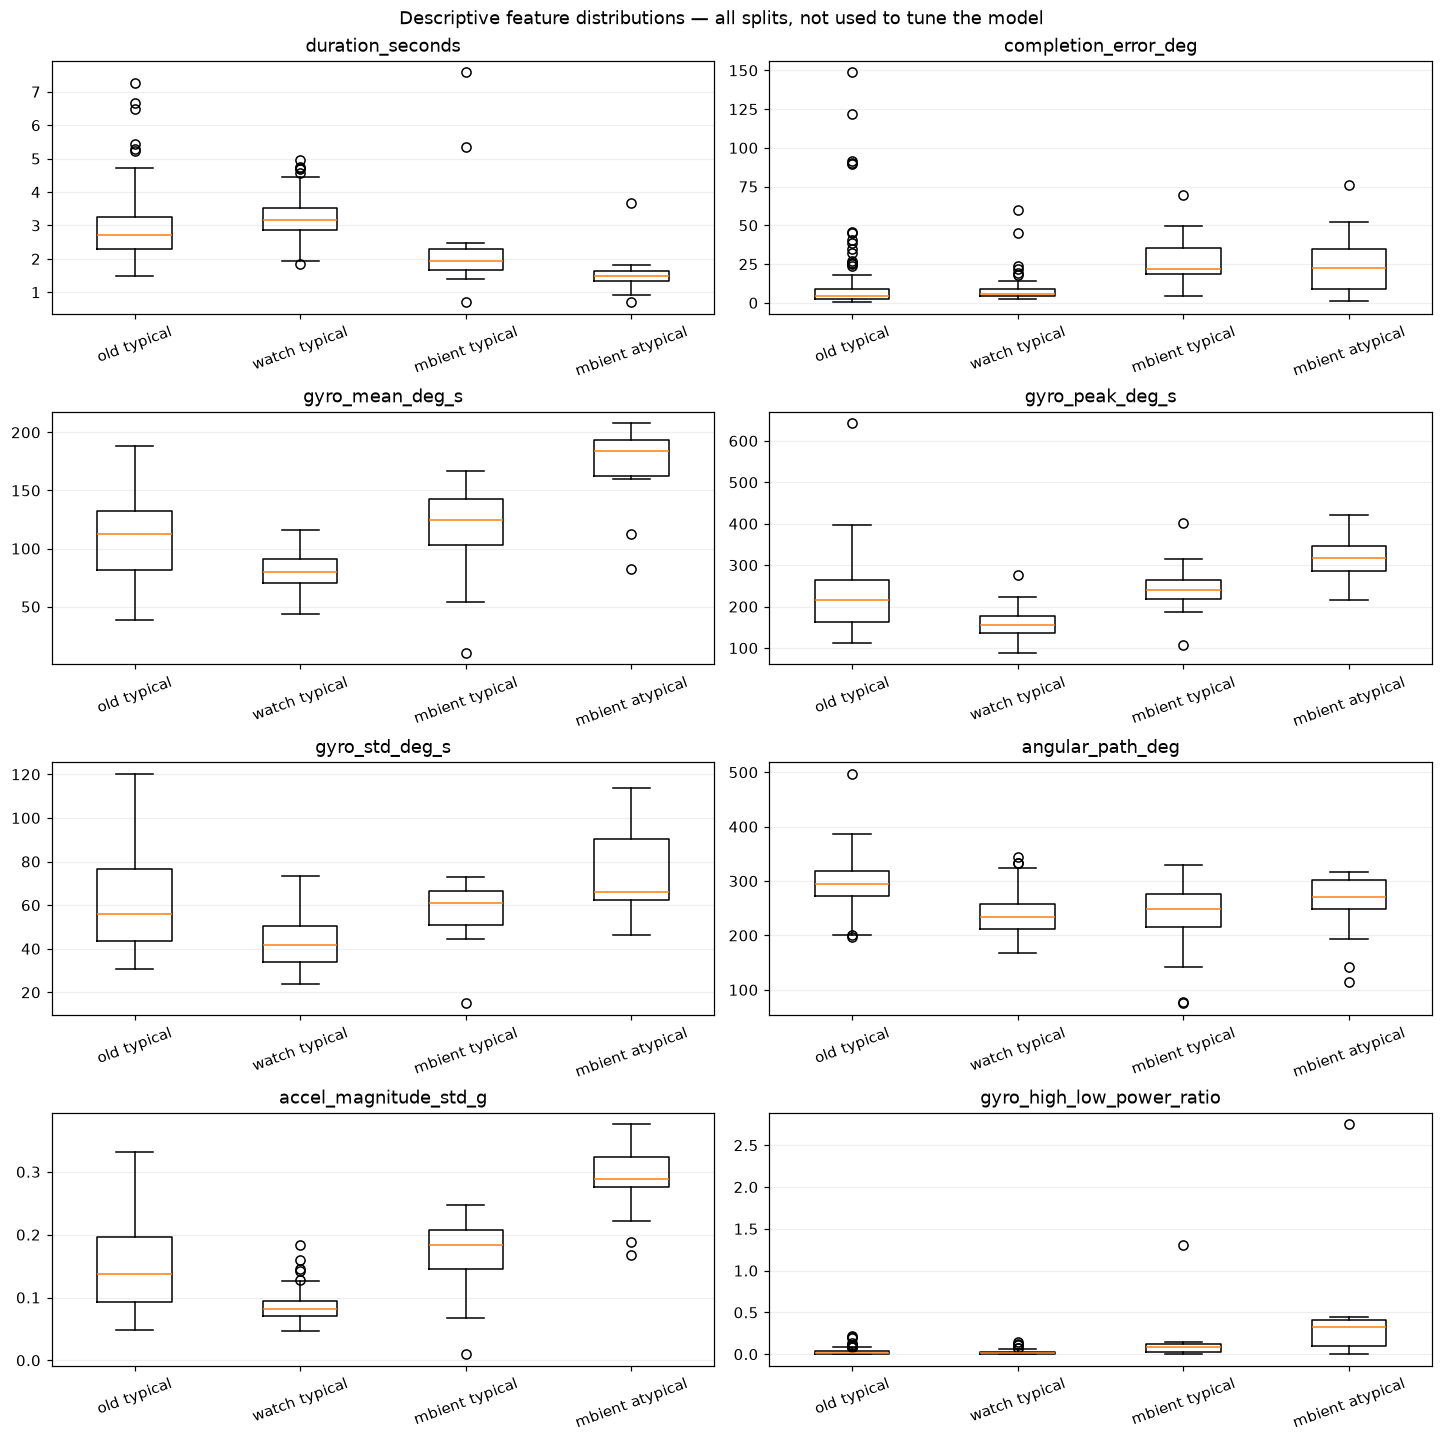

In [10]:
fig,axes=plt.subplots(4,2,figsize=(13,13),constrained_layout=True)
for j,ax in enumerate(axes.flat):
    groups=[];labels=[]
    for source,label in [('old',0),('watch',0),('mbient',0),('mbient',1)]:
        mask=(sources==source)&(y==label)
        if mask.any():groups.append(X[mask,j]);labels.append(source+(' typical' if label==0 else ' atypical'))
    ax.boxplot(groups,tick_labels=labels,showfliers=True)
    ax.set_title(FEATURES[j]);ax.tick_params(axis='x',labelrotation=20);ax.grid(axis='y',alpha=.2)
fig.suptitle('Descriptive feature distributions — all splits, not used to tune the model')
fig.savefig(OUTPUT/'feature_distributions.png',dpi=110)
plt.show()


### Explanation you can use
We replaced axis-specific angle features with motion-magnitude features and start-to-end rotation error. We trained a candidate Isolation Forest on typical repetitions, chose its threshold using separate validation participants, and tested held-out recordings plus the available Mbient examples. This reduces dependence on sensor-axis orientation, while cross-device and live performance still require verification.

## What this run tells us
The pooled candidate used 162 typical training repetitions from nine dataset-local participant groups. Its held-out old data contained 28 typical candidates (0 flagged) and 27 atypical candidates (17 detected). All nine assumed-typical watch candidates from one held-out participant were accepted; **this does not measure atypical watch sensitivity**. On the external Mbient recordings, it flagged 1/14 typical and detected 4/16 atypical candidates. The old-only comparison detected 9/16 Mbient atypical candidates, so pooling did not improve every outcome.

These are **candidate-segment scores**, not validated repetition or clinical accuracy. Visual inspection found plausible full-cycle watch boundaries, but initial setup can enter the first candidate and final unconfirmed cycles are omitted. Mbient typical segmentation includes setup and irregular boundaries. Old atypical validation rejected 41 candidates and accepted 15; atypical test rejected 11 and accepted 27. These exclusions can bias measured sensitivity. Review plots and rejection tables before interpreting performance. The split was reused from earlier experiments and is exploratory, not a fresh final benchmark.

The current conclusion is to retain this reproducible experiment and keep the active model unchanged. Do not adjust parameters on this test set and then call the new result an untouched test. Existing recordings can be annotated to improve boundary assessment without collecting more data.
